# UC Berkeley ML-AI-Cert - Capstone Project
# Detecting fraud in Agentic Payments - Working workbook
# Paul Beare


In [37]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [38]:
# import the csv dataset that was generated by the generate_10k_agentic_payments_transactions_with_fraud_network_info_and_statistical_noise Jupyter notebook

df = pd.read_csv('data/noisy_agentic_payments_10k.csv')

# visualize main characteristics of the dataset
df.head()
df.info()
df.describe()    

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      10000 non-null  object 
 1   Timestamp           10000 non-null  object 
 2   Agent_ID            10000 non-null  object 
 3   Agent_Name          10000 non-null  object 
 4   Agent_Type          10000 non-null  object 
 5   Amount_USD          10000 non-null  float64
 6   Trigger_Reason      10000 non-null  object 
 7   Originating_IP      10000 non-null  object 
 8   API_Version         10000 non-null  object 
 9   Server_Region       10000 non-null  object 
 10  Payment_Rail        10000 non-null  object 
 11  Is_Anomalous_Fraud  10000 non-null  int64  
dtypes: float64(1), int64(1), object(10)
memory usage: 937.6+ KB


,Amount_USD,Is_Anomalous_Fraud
count,10000.000000,10000.000000
mean,1350.251308,0.032000
std,5024.082603,0.176009
min,0.010000,0.000000
25%,12.017500,0.000000
50%,59.085000,0.000000
75%,1027.780000,0.000000
max,39793.220000,1.000000


In [39]:

# check for missing values
df.isnull().sum()

# list values of each column
for col in df.columns:
    print(f"Values of {col}:")
    print(df[col].unique())
    

Values of Transaction_ID:
['TXN-1000000' 'TXN-1000001' 'TXN-1000002' ... 'TXN-1009997' 'TXN-1009998'
 'TXN-1009999']
Values of Timestamp:
['2026-09-22 00:21:01' '2026-09-22 00:25:31' '2026-09-22 00:30:16' ...
 '2026-10-21 23:48:07' '2026-10-21 23:53:52' '2026-10-21 23:55:33']
Values of Agent_ID:
['AGNT-UTIL-02' 'AGNT-API-05' 'AGNT-SHOP-03' 'AGNT-FIN-01' 'AGNT-AD-04']
Values of Agent_Name:
['AutoUtilityOptimizer' 'LLM-MeteredPay' 'ProcurementBot'
 'PortfolioRebalancer' 'AdSpendOptimizer']
Values of Agent_Type:
['SaaS / Bills' 'API / Infrastructure' 'Inventory Supply'
 'DeFi / Investment' 'Marketing']
Values of Amount_USD:
[ 22.68   3.5    9.56 ... 119.33 415.99  51.89]
Values of Trigger_Reason:
['Contract Renewal Auto-Negotiated' 'Token Pool Replenishment'
 'Rapid Request Reset' 'Bulk Discount Match'
 'Scheduled Portfolio Rebalance' 'Threshold Trigger: Asset Dip'
 'Compute Node Scaling' 'Bid Cap Adjustment' 'Direct Instruction Override'
 'Usage Threshold Reached' 'Stock Level < 15%' 'Dy

In [40]:
# Display the entire dataset
df

,Transaction_ID,Timestamp,Agent_ID,Agent_Name,Agent_Type,Amount_USD,Trigger_Reason,Originating_IP,API_Version,Server_Region,Payment_Rail,Is_Anomalous_Fraud
0,TXN-1000000,2026-09-22 00:21:01,AGNT-UTIL-02,AutoUtilityOptimizer,SaaS / Bills,22.68,Contract Renewal Auto-Negotiated,185.220.101.5,v2.0-stable,eu-central-1,Stripe Link,0
1,TXN-1000001,2026-09-22 00:25:31,AGNT-API-05,LLM-MeteredPay,API / Infrastructure,3.50,Token Pool Replenishment,192.168.1.50,v2.0-stable,us-east-1,Stripe Link,0
2,TXN-1000002,2026-09-22 00:30:16,AGNT-API-05,LLM-MeteredPay,API / Infrastructure,9.56,Rapid Request Reset,192.168.1.50,v2.1-beta,us-east-1,USDC Stablecoin,0
3,TXN-1000003,2026-09-22 00:33:33,AGNT-SHOP-03,ProcurementBot,Inventory Supply,273.92,Bulk Discount Match,185.220.101.5,v2.0-stable,eu-central-1,USDC Stablecoin,0
4,TXN-1000004,2026-09-22 00:33:52,AGNT-FIN-01,PortfolioRebalancer,DeFi / Investment,1695.05,Scheduled Portfolio Rebalance,12.44.192.103,v2.0-stable,eu-central-1,FedNow,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN-1009995,2026-10-21 23:46:16,AGNT-API-05,LLM-MeteredPay,API / Infrastructure,7.89,Rapid Request Reset,12.44.192.103,v2.1-beta,us-east-1,USDC Stablecoin,0
9996,TXN-1009996,2026-10-21 23:48:03,AGNT-API-05,LLM-MeteredPay,API / Infrastructure,11.17,Token Pool Replenishment,185.220.101.5,v2.0-stable,eu-central-1,USDC Stablecoin,1
9997,TXN-1009997,2026-10-21 23:48:07,AGNT-API-05,LLM-MeteredPay,API / Infrastructure,11.98,Token Pool Replenishment,104.244.42.1,v2.0-stable,us-east-1,FedNow,0
9998,TXN-1009998,2026-10-21 23:53:52,AGNT-UTIL-02,AutoUtilityOptimizer,SaaS / Bills,34.54,Contract Renewal Auto-Negotiated,192.168.1.50,v2.1-beta,eu-central-1,FedNow,0


## Data preparation 

After visualizing the columns and row samples of the data we determine:
- The target column is the Is_Anomalous_Fraud column which shows a 0 for non-fraudulent transaction and a 1 for a fraudulent transaction.
- There is no missing data
- The Transaction_ID column adds no valuable information to the determination of fraud and will probably confuse and add unnecessary processing time to any model, so we will drop it
- The Timestamp column, which could be valuable as a feature to predict trends or estimate future fraud, will not be useful in our particular analysis of find patters in the transaction data itself, so we will also drop it

In [41]:
#drop Transaction_ID and Timestamp columns
df = df.drop(columns=['Transaction_ID', 'Timestamp'])
df.head()

,Agent_ID,Agent_Name,Agent_Type,Amount_USD,Trigger_Reason,Originating_IP,API_Version,Server_Region,Payment_Rail,Is_Anomalous_Fraud
0,AGNT-UTIL-02,AutoUtilityOptimizer,SaaS / Bills,22.68,Contract Renewal Auto-Negotiated,185.220.101.5,v2.0-stable,eu-central-1,Stripe Link,0
1,AGNT-API-05,LLM-MeteredPay,API / Infrastructure,3.50,Token Pool Replenishment,192.168.1.50,v2.0-stable,us-east-1,Stripe Link,0
2,AGNT-API-05,LLM-MeteredPay,API / Infrastructure,9.56,Rapid Request Reset,192.168.1.50,v2.1-beta,us-east-1,USDC Stablecoin,0
3,AGNT-SHOP-03,ProcurementBot,Inventory Supply,273.92,Bulk Discount Match,185.220.101.5,v2.0-stable,eu-central-1,USDC Stablecoin,0
4,AGNT-FIN-01,PortfolioRebalancer,DeFi / Investment,1695.05,Scheduled Portfolio Rebalance,12.44.192.103,v2.0-stable,eu-central-1,FedNow,0


## Data visualization

To get a better feel with respect to the data, possible biases and more significant columns, we explore different visualization of the data using charts.

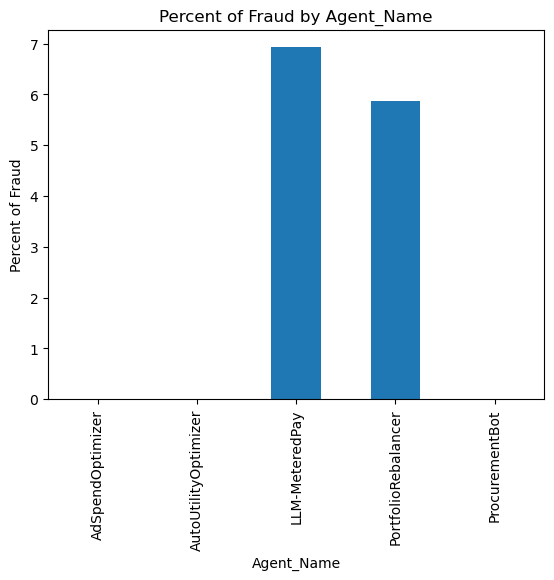

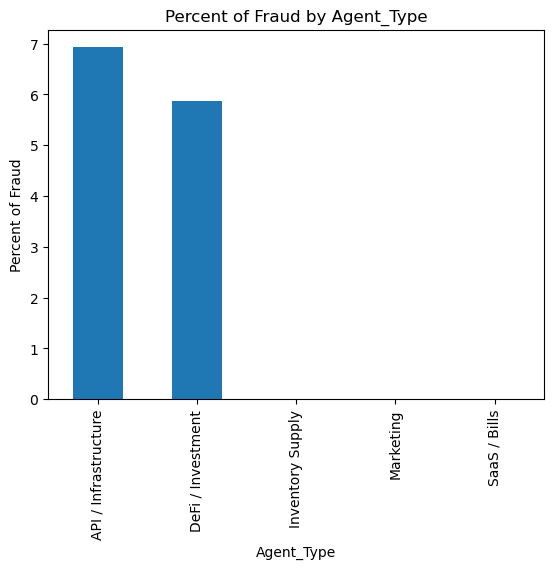

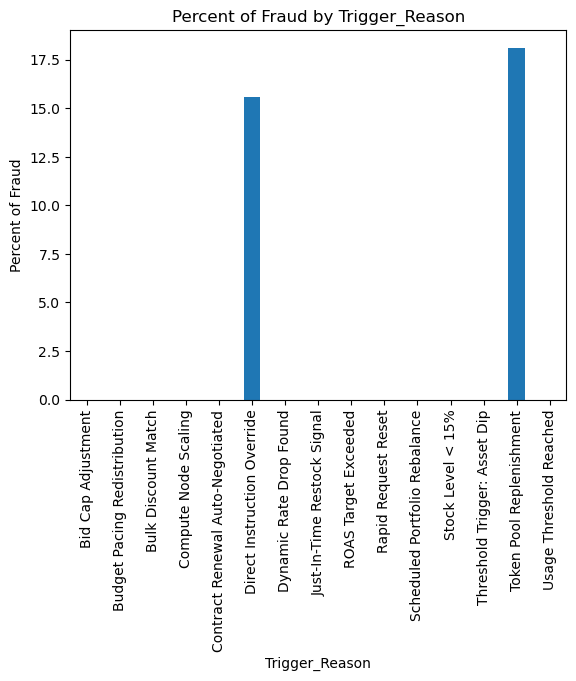

In [42]:
# visualize percent of fraud for key columns
import matplotlib.pyplot as plt
key_columns = ['Agent_Name', 'Agent_Type', 'Trigger_Reason']  
for col in key_columns:
    fraud_percent = df.groupby(col)['Is_Anomalous_Fraud'].mean() * 100
    fraud_percent.plot(kind='bar')
    plt.title(f'Percent of Fraud by {col}')
    plt.ylabel('Percent of Fraud')
    plt.show()
    

Analyzing the three charts above, we conclude that some of the columns are particularly significant in the determination of fraud, so we get a feeling that Machine Learning will help us to determine which combination of these columns or specific values of data have more influence or better identify fraudulent transactions.

We continue preparing the data.  Since Machine Learning models can only process numbers and not text, we need to encode all of the values in all of the columns using One Hot Encoding.

In [43]:
# one hot encode all non-numeric columns
df_encoded = pd.get_dummies(df, drop_first=True)

In [44]:
# visualize the first few rows of the encoded dataset
df_encoded.head()

,Amount_USD,Is_Anomalous_Fraud,Agent_ID_AGNT-API-05,Agent_ID_AGNT-FIN-01,Agent_ID_AGNT-SHOP-03,Agent_ID_AGNT-UTIL-02,Agent_Name_AutoUtilityOptimizer,Agent_Name_LLM-MeteredPay,Agent_Name_PortfolioRebalancer,Agent_Name_ProcurementBot,...,Originating_IP_12.44.192.103,Originating_IP_185.220.101.5,Originating_IP_192.168.1.50,Originating_IP_45.79.10.4,API_Version_v2.0-stable,API_Version_v2.1-beta,Server_Region_eu-central-1,Server_Region_us-east-1,Payment_Rail_Stripe Link,Payment_Rail_USDC Stablecoin
0,22.68,0,False,False,False,True,True,False,False,False,...,False,True,False,False,True,False,True,False,True,False
1,3.50,0,True,False,False,False,False,True,False,False,...,False,False,True,False,True,False,False,True,True,False
2,9.56,0,True,False,False,False,False,True,False,False,...,False,False,True,False,False,True,False,True,False,True
3,273.92,0,False,False,True,False,False,False,False,True,...,False,True,False,False,True,False,True,False,False,True
4,1695.05,0,False,True,False,False,False,False,True,False,...,True,False,False,False,True,False,True,False,False,False


In [45]:
# analyze correlation with each feature with Is_Anomalous_Fraud
correlation_with_target = df_encoded.corr()['Is_Anomalous_Fraud'].sort_values(ascending=False)
correlation_with_target

Is_Anomalous_Fraud                                 1.000000
Amount_USD                                         0.391647
Trigger_Reason_Token Pool Replenishment            0.298556
Originating_IP_185.220.101.5                       0.267741
Trigger_Reason_Direct Instruction Override         0.203050
Agent_ID_AGNT-API-05                               0.134932
Agent_Name_LLM-MeteredPay                          0.134932
Agent_ID_AGNT-FIN-01                               0.076977
Agent_Name_PortfolioRebalancer                     0.076977
Agent_Type_DeFi / Investment                       0.076977
Server_Region_eu-central-1                         0.016086
Payment_Rail_USDC Stablecoin                       0.005473
API_Version_v2.1-beta                              0.005069
Payment_Rail_Stripe Link                          -0.002933
API_Version_v2.0-stable                           -0.004083
Server_Region_us-east-1                           -0.011480
Trigger_Reason_ROAS Target Exceeded     

An important tool to continue to understand the data and most influential values and columns is to find the correlation between the target column and all of the other columns, as shown above.  In this case, because we have a large number of columns we decide not to create a heatmap visualization which would be hard to interprent, and rather we decide to show the actual numbers of correlations in descending order.  
The conclusion is not an obvious one at first, showing that the value (Amount_USD) of the transaction is the column most highly correlated with fraud in our dataset.  This is not necessarily the case in the real world, when precisely most of the fraudsters try to send many "small" transactions supposing that the fraud detection systems would first flag the high value transactions.

## Find the baseline

Before we begin selecting, training and evaluating the models, we determine a way to select a baseline accuracy.  Since this an imbalanced model with only a small (3.2%) of transactions being the target, a model which predicts 96.8% of transactions as non-fraudulent would basically be useless.  We verify that the baseline accuracy is 96.8% in the calculations below.

In [46]:
# find baseline by calculating the mean of the target variable
baseline = df['Is_Anomalous_Fraud'].mean()

baseline_accuracy = 1-baseline
print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.968


We continue viualizing the columns values and ranges, but separating the fraudulent and non-fraudulent transactions, but no additional insight is obtained.

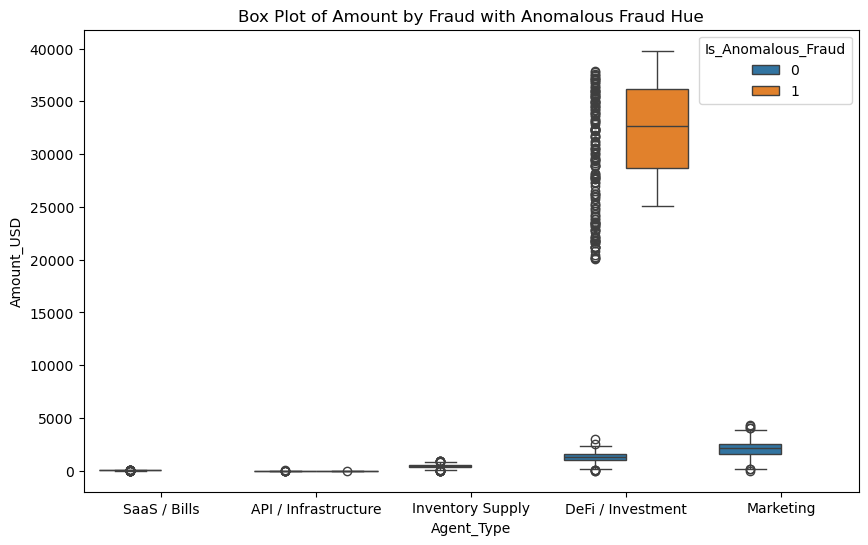

In [47]:
# plot box plot of Amount column with hue based on Fraud column
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.boxplot(x='Agent_Type', y='Amount_USD', hue='Is_Anomalous_Fraud', data=df)
plt.title("Box Plot of Amount by Fraud with Anomalous Fraud Hue")
plt.show()


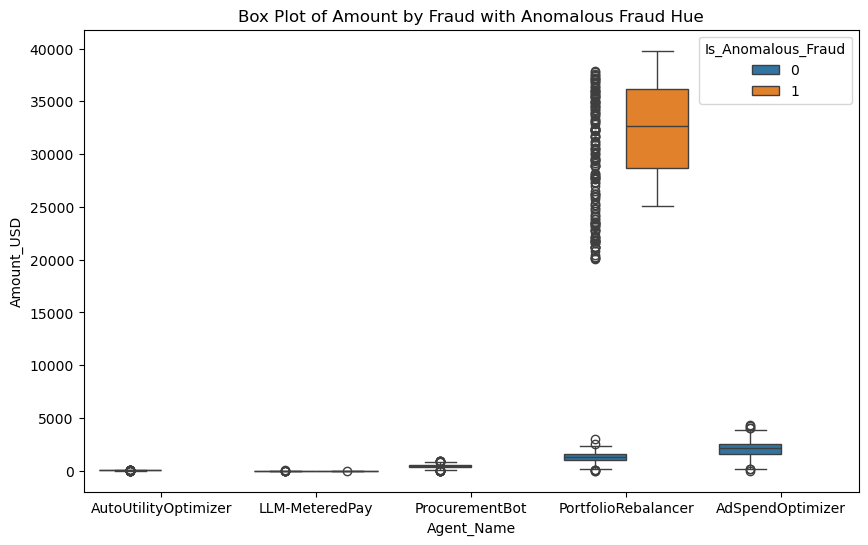

In [48]:
# plot box plot of Amount column with Agent_Name on x-axis and hue based on Fraud column
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.boxplot(x='Agent_Name', y='Amount_USD', hue='Is_Anomalous_Fraud', data=df)
plt.title("Box Plot of Amount by Fraud with Anomalous Fraud Hue")
plt.show()

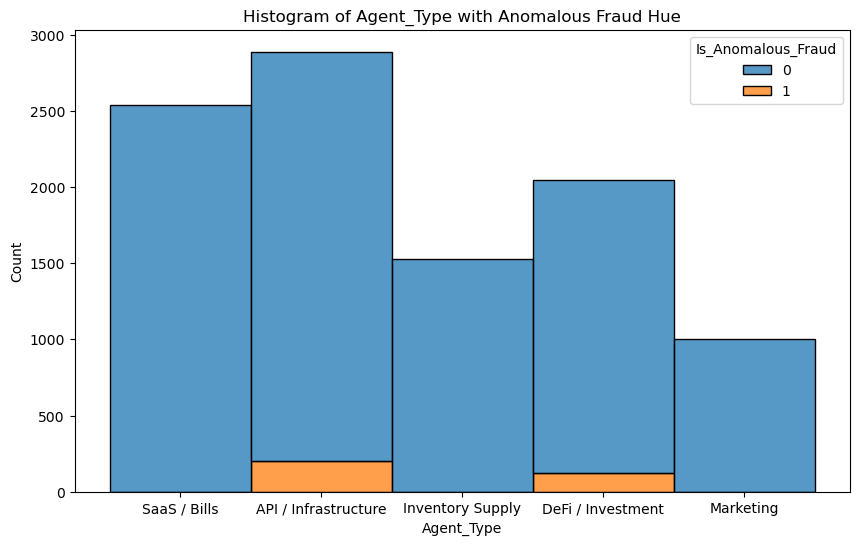

In [49]:
# plot histogram of Agent_Type column
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Agent_Type', hue='Is_Anomalous_Fraud', multiple='stack')
plt.title("Histogram of Agent_Type with Anomalous Fraud Hue")
plt.show()

## Splitting the data into training and testing datasets


In [50]:
# Divide the dataset into features and target variable
X = df_encoded.drop(columns=['Is_Anomalous_Fraud'])
y = df_encoded['Is_Anomalous_Fraud']

In [51]:
# Create training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)
print("Training target size:", y_train.shape)
print("Testing target size:", y_test.shape)

Training set size: (8000, 37)
Testing set size: (2000, 37)
Training target size: (8000,)
Testing target size: (2000,)


We have verified that the training set contains 8000 of the 10000 records, and the testing set contains 2000 of the records. Only the training records will be used to train the models and the testing dataset will be used to verify if the models work or are useful.

We prepare a dataframe (table) which we will use to store and later review and compare all the results of our model comparisons.

In [52]:
# create a dataframe that will store the Accuracy, Precision, Recall and F1 Scores and model name for each model

metrics_df = pd.DataFrame(columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
# visualize the first few rows of the metrics dataframe
metrics_df.head()

,Model,Accuracy,Precision,Recall,F1 Score


## Modeling and result visualization with confusion matrix

We begin with Logistic Regression model on the training data, and then measure it's ability to predict fraud with the testing dataset.

For each model we will also plot the confusion matrix.
A confusion matrix is a table that compares a classification model's predictions against actual ground-truth values, breaking them down into four core outcomes: True Positives (TP), True Negatives (TN), False Positives (FP), and False Negatives (FN).
It is a powerful visualization tool for several reasons:

• Reveals the "Type" of Error: While a single accuracy score just tells you how often a model was right, a confusion matrix shows how it is failing—distinguishing between false alarms (False Positives) and missed detections (False Negatives).

• Handles Imbalanced Datasets: If 99% of your data belongs to one class, a model can hit 99% accuracy by simply guessing that class every time. A confusion matrix exposes this immediately by showing poor performance on the minority class.

• Powers Deeper Metrics: It serves as the foundational building block for calculating critical performance metrics like Precision, Recall, Specificity, and F1-Score.



Accuracy: 0.976
Precision: 0.7017543859649122
Recall: 0.5633802816901409
F1 Score: 0.625


c:\Users\paulb\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


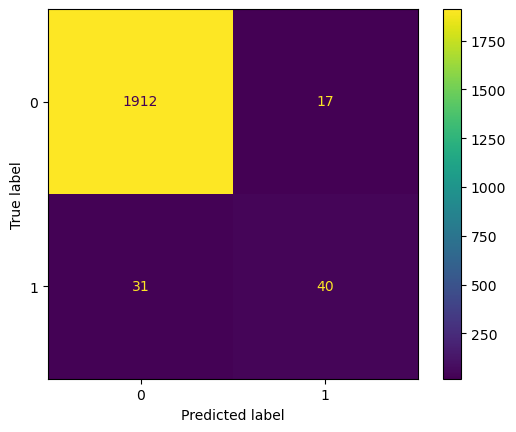

In [53]:
# create a Logistic Regression model and evaluate accuracy metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy_lr = accuracy_score(y_test, y_pred)
precision_lr = precision_score(y_test, y_pred)
recall_lr = recall_score(y_test, y_pred)
f1_lr = f1_score(y_test, y_pred)

print("Accuracy:", accuracy_lr)
print("Precision:", precision_lr)
print("Recall:", recall_lr)
print("F1 Score:", f1_lr)

# show the confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()


In [54]:
# append the result to the metrics_df dataframe using .concat
metrics_df = pd.concat([metrics_df, pd.DataFrame([{
    "Model": "Logistic Regression",
    "Accuracy": accuracy_lr,
    "Precision": precision_lr,
    "Recall": recall_lr,
    "F1 Score": f1_lr
}])], ignore_index=True)    
metrics_df


C:\Users\paulb\AppData\Local\Temp\ipykernel_115056\1454922666.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  metrics_df = pd.concat([metrics_df, pd.DataFrame([{


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.976,0.701754,0.56338,0.625


In [55]:
# now do the same but with Decision Tree as the model
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy_dt = model.score(X_test, y_test)
from sklearn.metrics import precision_score
precision_dt = precision_score(y_test, y_pred)
from sklearn.metrics import recall_score
recall_dt = recall_score(y_test, y_pred)
from sklearn.metrics import f1_score
f1_dt = f1_score(y_test, y_pred)

print("Accuracy:", accuracy_dt)
print("Precision:", precision_dt)
print("Recall:", recall_dt)
print("F1 Score:", f1_dt)

Accuracy: 0.9785
Precision: 0.7258064516129032
Recall: 0.6338028169014085
F1 Score: 0.6766917293233082


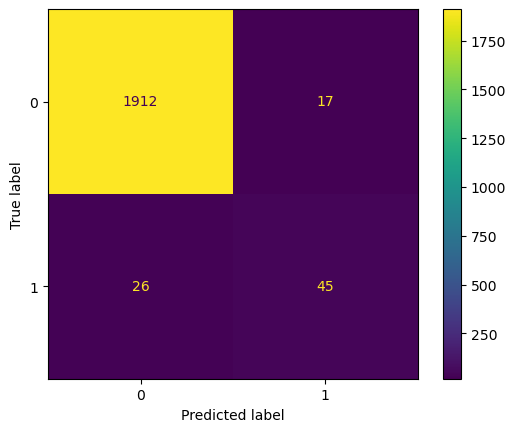

In [56]:
# show the confusion matrix of the previous model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [57]:
# append the result to the metrics_df dataframe using .concat
metrics_df = pd.concat([metrics_df, pd.DataFrame([{
    "Model": "Decision Tree",
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt,
    "F1 Score": f1_dt
}])], ignore_index=True) 
metrics_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9760,0.701754,0.563380,0.625000
1,Decision Tree,0.9785,0.725806,0.633803,0.676692


In [58]:
# now use Random Forest as the model
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy_rf = model.score(X_test, y_test)
from sklearn.metrics import precision_score
precision_rf = precision_score(y_test, y_pred)
from sklearn.metrics import recall_score
recall_rf = recall_score(y_test, y_pred)
from sklearn.metrics import f1_score
f1_rf = f1_score(y_test, y_pred)

print("Accuracy:", accuracy_rf)
print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)

Accuracy: 0.9815
Precision: 0.7297297297297297
Recall: 0.7605633802816901
F1 Score: 0.7448275862068966


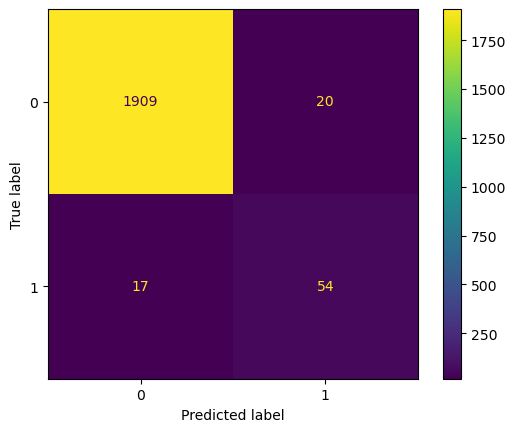

In [59]:
# show the confusion matrix of the previous model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [60]:
# append the result to the metrics_df dataframe using .concat
metrics_df = pd.concat([metrics_df, pd.DataFrame([{
    "Model": "Random Forest",
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1 Score": f1_rf
}])], ignore_index=True) 
metrics_df.head()

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9760,0.701754,0.563380,0.625000
1,Decision Tree,0.9785,0.725806,0.633803,0.676692
2,Random Forest,0.9815,0.729730,0.760563,0.744828


In [61]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model = RandomForestClassifier(random_state=42)

params = {
    "n_estimators": [200, 500],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"],
}

search = GridSearchCV(
    model,
    params,
    scoring={"accuracy": "accuracy", "precision": "precision"},
    refit="precision",
    cv=5,
    n_jobs=-1,
)

search.fit(X_train, y_train)
print(search.best_params_)
print(search.best_score_)
y_pred = search.predict(X_test)

accuracy_gs = accuracy_score(y_test, y_pred)
precision_gs = precision_score(y_test, y_pred)
recall_gs = recall_score(y_test, y_pred)
f1_gs = f1_score(y_test, y_pred)

print("Accuracy:", accuracy_gs)
print("Precision:", precision_gs)
print("Recall:", recall_gs)
print("F1 Score:", f1_gs)

{'class_weight': None, 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 500}
0.6792698775618403
Accuracy: 0.9815
Precision: 0.717948717948718
Recall: 0.7887323943661971
F1 Score: 0.7516778523489933


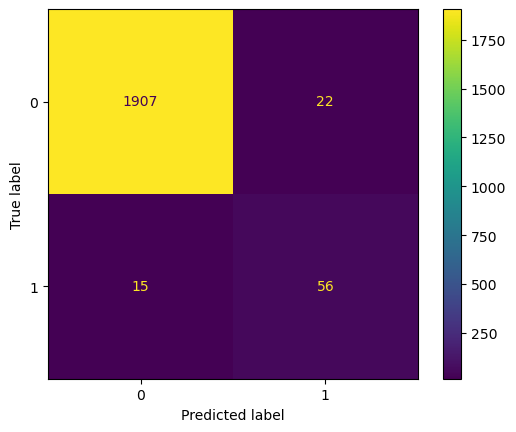

In [62]:
# show the confusion matrix of the previous model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [63]:
# append the result to the metrics_df dataframe using .concat
metrics_df = pd.concat([metrics_df, pd.DataFrame([{
    "Model": "Grid Search Decision Tree",
    "Accuracy": accuracy_gs,
    "Precision": precision_gs,
    "Recall": recall_gs,
    "F1 Score": f1_gs
}])], ignore_index=True) 
metrics_df



,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9760,0.701754,0.563380,0.625000
1,Decision Tree,0.9785,0.725806,0.633803,0.676692
2,Random Forest,0.9815,0.729730,0.760563,0.744828
3,Grid Search Decision Tree,0.9815,0.717949,0.788732,0.751678


In [64]:
# now use SMOTE to balance the classes and try again with Random Forest and GridSearchCV
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)

params = {
    "n_estimators": [200, 500],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 5],
    "class_weight": [None, "balanced"],
}

search = GridSearchCV(
    model,
    params,
    scoring={"accuracy": "accuracy", "precision": "precision"},
    refit="precision",
    cv=5,
    n_jobs=-1,
)

search.fit(X_train_res, y_train_res)
print(search.best_params_)
print(search.best_score_)
y_pred = search.predict(X_test)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy_smote = accuracy_score(y_test, y_pred)
precision_smote = precision_score(y_test, y_pred)
recall_smote = recall_score(y_test, y_pred)
f1_smote = f1_score(y_test, y_pred)
print("Accuracy:", accuracy_smote)
print("Precision:", precision_smote)
print("Recall:", recall_smote)
print("F1 Score:", f1_smote)

{'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
0.9868142519465897
Accuracy: 0.9845
Precision: 0.7380952380952381
Recall: 0.8732394366197183
F1 Score: 0.8


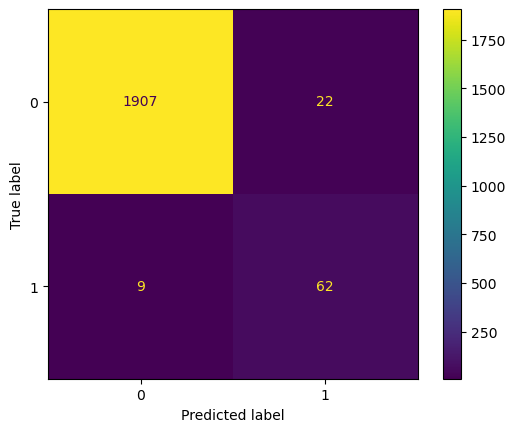

In [65]:
# show the confusion matrix of the previous model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()


In [66]:
# append the result to the metrics_df dataframe using .concat
metrics_df = pd.concat([metrics_df, pd.DataFrame([{
    "Model": "SMOTE Random Forest",
    "Accuracy": accuracy_smote,
    "Precision": precision_smote,
    "Recall": recall_smote,
    "F1 Score": f1_smote
}])], ignore_index=True) 
metrics_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9760,0.701754,0.563380,0.625000
1,Decision Tree,0.9785,0.725806,0.633803,0.676692
2,Random Forest,0.9815,0.729730,0.760563,0.744828
3,Grid Search Decision Tree,0.9815,0.717949,0.788732,0.751678
4,SMOTE Random Forest,0.9845,0.738095,0.873239,0.800000


In [67]:
# Use SVC to improve the model
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = df_encoded.drop('Is_Anomalous_Fraud', axis=1)
y = df_encoded['Is_Anomalous_Fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

svc_model = SVC()
svc_model.fit(X_train, y_train)
y_pred = svc_model.predict(X_test)
accuracy_svc = accuracy_score(y_test, y_pred)
precision_svc = precision_score(y_test, y_pred)
recall_svc = recall_score(y_test, y_pred)
f1_svc = f1_score(y_test, y_pred)
print("SVC Accuracy:", accuracy_svc)
print("SVC Precision:", precision_svc)
print("SVC Recall:", recall_svc)
print("SVC F1 Score:", f1_svc)




SVC Accuracy: 0.9655
SVC Precision: 0.6666666666666666
SVC Recall: 0.056338028169014086
SVC F1 Score: 0.1038961038961039


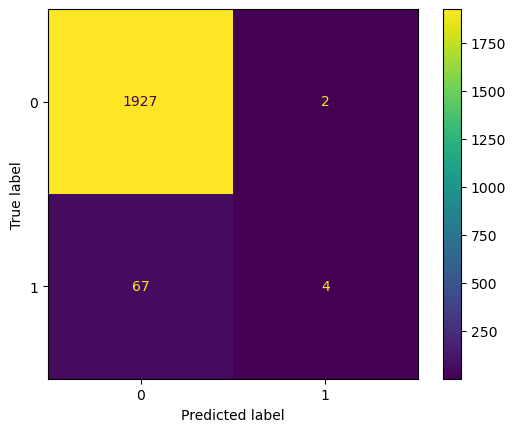

In [68]:
# visualize the confusion matrix for all the model used and compare them
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt 

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

In [69]:
# append the result to the metrics_df dataframe using .concat
metrics_df = pd.concat([metrics_df, pd.DataFrame([{
    "Model": "SVC",
    "Accuracy": accuracy_svc,
    "Precision": precision_svc,
    "Recall": recall_svc,
    "F1 Score": f1_svc
}])], ignore_index=True) 
metrics_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9760,0.701754,0.563380,0.625000
1,Decision Tree,0.9785,0.725806,0.633803,0.676692
2,Random Forest,0.9815,0.729730,0.760563,0.744828
3,Grid Search Decision Tree,0.9815,0.717949,0.788732,0.751678
4,SMOTE Random Forest,0.9845,0.738095,0.873239,0.800000
5,SVC,0.9655,0.666667,0.056338,0.103896


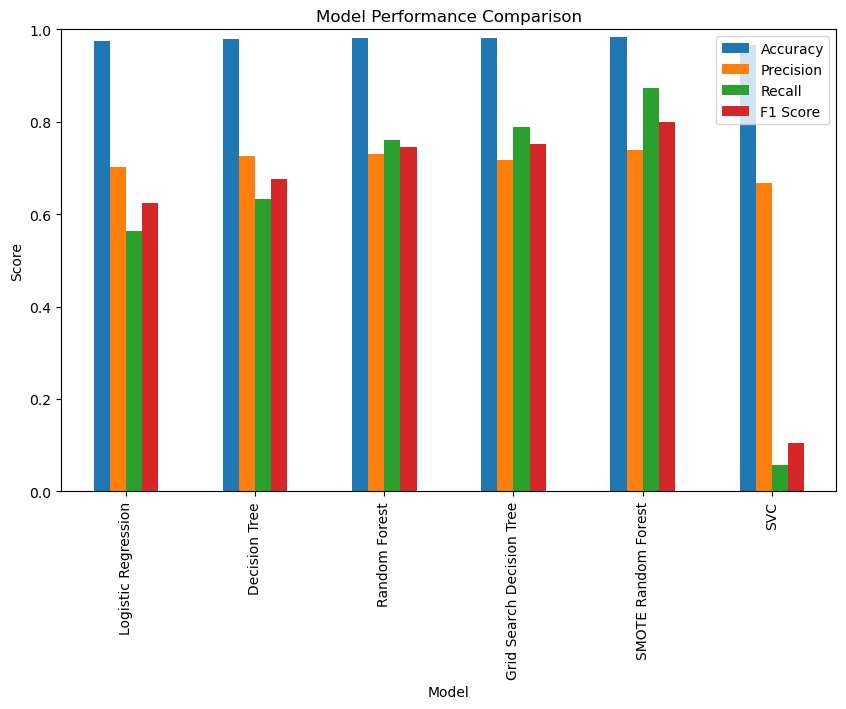

In [70]:
# plot the above table as a Bar Chart showing the Accuracy, Precision, Recall and F1 Score in the X axis and the score in the Y axis
import matplotlib.pyplot as plt
metrics_df.plot(x='Model', y=['Accuracy', 'Precision', 'Recall', 'F1 Score'], kind='bar', figsize=(10, 6))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.show()

## Conclusion

Based on the evaluation metrics stored in the `metrics_df` dataframe, we can compare the performance of different models. The model with the highest accuracy, precision, recall, and F1 score would be considered the best performing model for our task.

The image above showing how the F1 score improves when moving from left to right clearly shows which is the best model, and shows that last model (SVC) did not peform well.

1) This Project serves as an important advance to understand the application of Machine Learning algorithms to the detection of fraud in Agentic Payment transactions.
2) Working with generated synthetic data is not as useful or challenging as doing it with real world data, but for the reasons exposed above it was our only option for this project.
3) As a new and evolving technology, many more data sources could be used to complement the data examples used in this project, in particular the data sources related to the Agentic Commerce transaction, i.e. the data points related to the products or services purchased, merchant information, customer information, purchase history, customer address, etc. to make the process of identifying fraud much more complete and powerful.  However, the underlying models to be used and findings of this project would still apply to these new scenarios.
4) Of the model and parameters tried, the best performing model resulted in the Random Forest model using SMOTE to balance the dataset, achieving the following results, much surpassing the baseline model:

Accuracy:  0.9845 

Precision: 0.738095

Recall:    0.873239 

F1 score:  0.800000


## Additional steps

Once a useful and accurate model has been selected, as in the process described above, one could place the model in production, so that it could be used in the real world with real transactions.  

To turn a trained machine learning model into a callable REST API, we should follow these core steps:

• Save the Model: Serialize our trained model into a file (such as using joblib or pickle for scikit-learn, or native save formats for PyTorch/TensorFlow).

• Build an API Application: Write a lightweight web service using a framework like FastAPI or Flask. Define a data schema (e.g., via Pydantic in FastAPI) to validate incoming request payloads.

• Create a Prediction Endpoint: Write an HTTP POST route in your app that loads the saved model, preprocesses incoming request data, runs .predict(), and returns the output as JSON.

• Containerize the Service: Write a Dockerfile that packages your Python runtime, required dependencies (requirements.txt), the API script, and the model artifact into an isolated container image.

• Deploy and Test: Run the container locally or push it to a cloud hosting platform (such as AWS, Google Cloud Run, or Render), then test your live endpoint using curl, Python requests, or the interactive Swagger docs (/docs)

